# IoT Traffic Pipeline — Training and Evaluation

This notebook trains the three-phase pipeline, selects the causal context length without touching the test set, verifies Phase 3-to-Phase 2 gradient feedback, evaluates future-day and held-out-capture behavior, and saves a reusable inference bundle.

In [1]:
from pathlib import Path
import json, sys, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import Markdown, display
from sklearn.metrics import fbeta_score, precision_score, recall_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.multiclass import OneVsRestClassifier

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT))
from src.iot_pipeline import *

DERIVED = PROJECT / "derived"
PREPARED = DERIVED / "prepared"
SECOND_DIR = DERIVED / "secondly"
MODEL_DIR = PROJECT / "artifacts" / "models"
FIGURE_DIR = PROJECT / "artifacts" / "figures"
CACHE_DIR = PREPARED / "window_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(PREPARED / "capture_manifest.csv")
labels = pd.read_parquet(PREPARED / "canonical_labels.parquet")
seed_everything()
print(f"Captures={len(manifest)}, canonical labels={len(labels):,}, features contain no packet payloads.")

Captures=32, canonical labels=14,936, features contain no packet payloads.


/Users/duongtuanhoang/anaconda3/envs/phase34/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Leakage-resistant chronological split

Calendar boundaries are defined in Eastern time and converted to UTC. Window length, model thresholds, and calibration use only train/validation data. March 14–15 is opened once for final evaluation and includes the daylight-saving transition.

In [2]:
def eastern_utc(text):
    return pd.Timestamp(text, tz=LABEL_TZ).tz_convert("UTC")

TRAIN_START, TRAIN_END = eastern_utc("2021-03-08 00:00"), eastern_utc("2021-03-13 00:00") - pd.Timedelta(seconds=1)
VAL_START, VAL_END = eastern_utc("2021-03-13 00:00"), eastern_utc("2021-03-14 00:00") - pd.Timedelta(seconds=1)
TEST_START, TEST_END = eastern_utc("2021-03-14 00:00"), eastern_utc("2021-03-16 00:00") - pd.Timedelta(seconds=1)
assert TRAIN_END < VAL_START <= VAL_END < TEST_START
print("Train:", TRAIN_START, "to", TRAIN_END)
print("Validation:", VAL_START, "to", VAL_END)
print("Test:", TEST_START, "to", TEST_END)

Train: 2021-03-08 05:00:00+00:00 to 2021-03-13 04:59:59+00:00
Validation: 2021-03-13 05:00:00+00:00 to 2021-03-14 04:59:59+00:00
Test: 2021-03-14 05:00:00+00:00 to 2021-03-16 03:59:59+00:00


In [3]:
def cached_dataset(window, split, start, end, mode="sampled"):
    stem = CACHE_DIR / f"v2_{split}_{window}s_{mode}"
    npz_path, meta_path, schema_path = stem.with_suffix(".npz"), stem.with_suffix(".parquet"), stem.with_suffix(".json")
    if npz_path.exists() and meta_path.exists() and schema_path.exists():
        arrays = np.load(npz_path)
        return pd.read_parquet(meta_path), arrays["X"], arrays["yf"], arrays["yp"], json.loads(schema_path.read_text())
    meta, X, yf, yp, names = build_window_dataset(
        SECOND_DIR, manifest, labels, window, start, end, mode=mode, background_ratio=3
    )
    np.savez(npz_path, X=X, yf=yf, yp=yp)
    meta.to_parquet(meta_path, index=False)
    schema_path.write_text(json.dumps(names))
    return meta, X, yf, yp, names

## Phase 1 and causal window selection

For each candidate context, the decision threshold is the largest validation threshold achieving 95% event recall. Among contexts meeting that target, the shortest one within 0.01 F2 of the best is selected. This directly trades context against missed events instead of assuming that a longer trace is always better.

{'window': 5, 'threshold': 0.2788050696818146, 'precision': 0.29121813031161475, 'recall': 0.9508735868448098, 'f2': 0.6544065638704202, 'pr_auc': 0.7433171389949662, 'positive_rate': 0.760229720028715, 'feature_count': 86, 'train_windows': 84037, 'validation_windows': 20895}


{'window': 10, 'threshold': 0.281795051600755, 'precision': 0.31463273568536726, 'recall': 0.950938119100338, 'f2': 0.6770772830614514, 'pr_auc': 0.7796566861269963, 'positive_rate': 0.7136174779187189, 'feature_count': 129, 'train_windows': 154195, 'validation_windows': 36343}


{'window': 20, 'threshold': 0.27979815469577285, 'precision': 0.32835271094739266, 'recall': 0.9500399680255796, 'f2': 0.6890986925388711, 'pr_auc': 0.8112947422718015, 'positive_rate': 0.6903868773246018, 'feature_count': 172, 'train_windows': 276384, 'validation_windows': 62914}


{'window': 30, 'threshold': 0.30654202491422006, 'precision': 0.3517196165636019, 'recall': 0.9509893163416854, 'f2': 0.7092882819143994, 'pr_auc': 0.8180500977680253, 'positive_rate': 0.6473172298304773, 'feature_count': 215, 'train_windows': 390431, 'validation_windows': 87186}


,window,threshold,precision,recall,f2,pr_auc,positive_rate,feature_count,train_windows,validation_windows
0,5,0.278805,0.291218,0.950874,0.654407,0.743317,0.760230,86,84037,20895
1,10,0.281795,0.314633,0.950938,0.677077,0.779657,0.713617,129,154195,36343
2,20,0.279798,0.328353,0.950040,0.689099,0.811295,0.690387,172,276384,62914
3,30,0.306542,0.351720,0.950989,0.709288,0.818050,0.647317,215,390431,87186


Selected window: 30 seconds; 95% recall target met: True


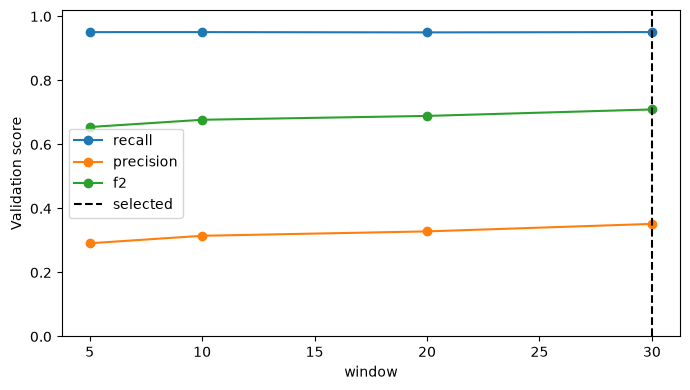

In [4]:
window_rows, phase1_models = [], {}
for window in WINDOWS:
    train_meta, X_train, yf_train, yp_train, names = cached_dataset(window, "train", TRAIN_START, TRAIN_END)
    val_meta, X_val, yf_val, yp_val, _ = cached_dataset(window, "validation", VAL_START, VAL_END)
    phase1_cache = CACHE_DIR / f"v3_phase1_{window}s.joblib"
    if phase1_cache.exists():
        model = joblib.load(phase1_cache)
    else:
        model = fit_phase1(X_train, train_meta.is_event.to_numpy())
        joblib.dump(model, phase1_cache)
    prob = model.predict_proba(X_val)[:, 1]
    threshold = threshold_for_recall(val_meta.is_event.to_numpy(), prob, 0.95)
    row = {"window": window, **binary_metrics(val_meta.is_event.to_numpy(), prob, threshold),
           "feature_count": len(names), "train_windows": len(train_meta), "validation_windows": len(val_meta)}
    window_rows.append(row)
    phase1_models[window] = model
    print(row)

window_results = pd.DataFrame(window_rows).sort_values("window")
selected_window, recall_target_met = select_window(window_results)
display(window_results)
print("Selected window:", selected_window, "seconds; 95% recall target met:", recall_target_met)

fig, ax = plt.subplots(figsize=(7, 4))
window_results.plot(x="window", y=["recall", "precision", "f2"], marker="o", ax=ax)
ax.axvline(selected_window, color="black", linestyle="--", label="selected")
ax.set_ylim(0, 1.02); ax.set_ylabel("Validation score"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURE_DIR / "window_selection.png", dpi=150); plt.show()

## Joint Phase 2–3 model

Phase 2 emits independent family probabilities because multiple child-device families can be active in one hub window. Phase 3 emits conditional family/event probabilities. Their product is trained against family-event targets, so event error flows through the Phase 2 probabilities; candidate thresholding is applied only after training.

In [5]:
train_meta, X_train, yf_train, yp_train, feature_names = cached_dataset(selected_window, "train", TRAIN_START, TRAIN_END)
val_meta, X_val, yf_val, yp_val, _ = cached_dataset(selected_window, "validation", VAL_START, VAL_END)
event_train = train_meta.is_event.to_numpy().astype(bool)
event_val = val_meta.is_event.to_numpy().astype(bool)

phase1 = phase1_models[selected_window]
val_phase1_prob = phase1.predict_proba(X_val)[:, 1]
phase1_threshold = threshold_for_recall(val_meta.is_event.to_numpy(), val_phase1_prob, 0.95)

joint_stem = CACHE_DIR / f"v3_joint_{selected_window}s"
if joint_stem.with_suffix(".pt").exists():
    cached_scaler = joblib.load(joint_stem.with_suffix(".scaler.joblib"))
    cached_history = pd.read_csv(joint_stem.with_suffix(".history.csv"))
    cached_compatibility = np.load(joint_stem.with_suffix(".compatibility.npy"))
    cached_model = JointFamilyEventModel(X_train.shape[1])
    cached_model.load_state_dict(torch.load(joint_stem.with_suffix(".pt"), map_location="cpu", weights_only=True))
    joint = JointTrainingResult(cached_model, cached_scaler, cached_history, cached_compatibility)
else:
    joint = fit_joint_model(
        X_train[event_train], yf_train[event_train], yp_train[event_train],
        X_val[event_val], yf_val[event_val], yp_val[event_val],
        max_epochs=100, patience=10, batch_size=512,
    )
    torch.save(joint.model.state_dict(), joint_stem.with_suffix(".pt"))
    joblib.dump(joint.scaler, joint_stem.with_suffix(".scaler.joblib"))
    joint.history.to_csv(joint_stem.with_suffix(".history.csv"), index=False)
    np.save(joint_stem.with_suffix(".compatibility.npy"), joint.compatibility)
family_prob_raw, pair_prob_raw = joint_predict(joint, X_val[event_val])
family_temperature = fit_temperature(family_prob_raw, yf_val[event_val])
pair_temperature = fit_temperature(pair_prob_raw[:, joint.compatibility.astype(bool)], yp_val[event_val][:, joint.compatibility.astype(bool)])
family_prob = apply_temperature(family_prob_raw, family_temperature)
pair_prob = apply_temperature(pair_prob_raw, pair_temperature)

family_threshold, family_coverage, mean_k = family_threshold_for_coverage(yf_val[event_val], family_prob, 0.95, 5)
compatibility = joint.compatibility.astype(bool)
pair_threshold = best_multilabel_threshold(yp_val[event_val][:, compatibility], pair_prob[:, compatibility])

feedback_gradient = gradient_feedback_check(joint, X_val[event_val], yp_val[event_val])
assert feedback_gradient > 0, "Phase 3 loss did not reach the Phase 2 family head."
assert candidate_mask(family_prob, family_threshold, 5).sum(axis=1).max() <= 5

print(f"Family temperature={family_temperature:.3f}; pair temperature={pair_temperature:.3f}")
print(f"Family threshold={family_threshold:.3f}; all-true-family coverage={family_coverage:.3f}; mean k={mean_k:.2f}")
print(f"Pair threshold={pair_threshold:.3f}; feedback gradient L1={feedback_gradient:.6f}")

Family temperature=2.154; pair temperature=1.832
Family threshold=0.566; all-true-family coverage=0.954; mean k=1.57
Pair threshold=0.470; feedback gradient L1=1.011621


## Independent baseline comparison

An independent one-vs-rest logistic pipeline provides a control. It does not propagate event loss into device-family prediction, so the comparison isolates whether the differentiable hierarchy is useful rather than merely more complicated.

,model,family_micro_f1,pair_micro_f1,pair_mAP
0,joint,0.772678,0.611523,0.748788
1,independent,0.613567,0.543609,0.605509


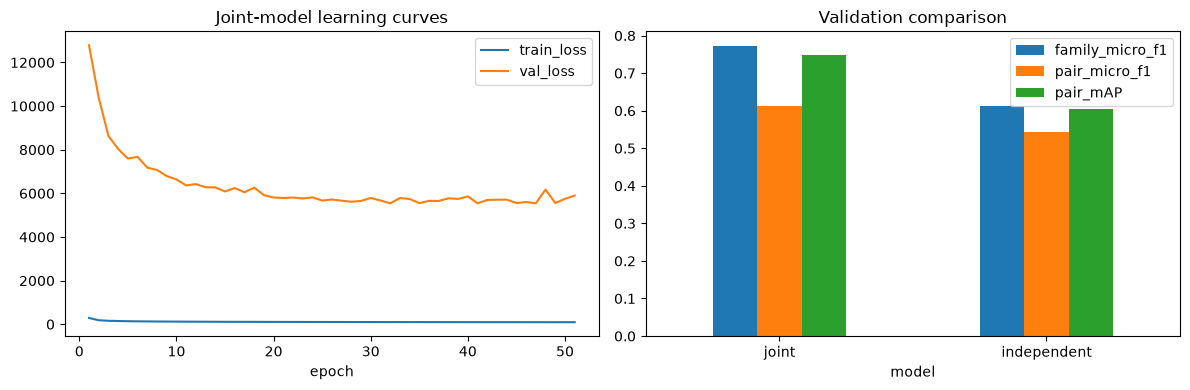

**Training observation.** The joint hierarchy improved validation family-event micro-F1 (0.612 versus 0.544). This is an important result: gradient feedback is verified mechanically, but whether it helps generalization is an empirical question.

In [6]:
baseline_cache = CACHE_DIR / f"v3_independent_{selected_window}s.joblib"
if baseline_cache.exists():
    baseline_scaler, baseline_family, baseline_pair = joblib.load(baseline_cache)
else:
    baseline_scaler, baseline_family, baseline_pair = fit_independent_baselines(
        X_train[event_train], yf_train[event_train], yp_train[event_train]
    )
    joblib.dump((baseline_scaler, baseline_family, baseline_pair), baseline_cache)
Xv_scaled = baseline_scaler.transform(X_val[event_val])
baseline_family_prob = baseline_family.predict_proba(Xv_scaled)
baseline_pair_prob = baseline_pair.predict_proba(Xv_scaled).reshape(-1, len(FAMILIES), len(EVENTS))
baseline_family_threshold, _, _ = family_threshold_for_coverage(yf_val[event_val], baseline_family_prob, 0.95, 5)
baseline_pair_threshold = best_multilabel_threshold(
    yp_val[event_val][:, compatibility], baseline_pair_prob[:, compatibility]
)

joint_family_metrics = multilabel_metrics(yf_val[event_val], family_prob, family_threshold)
baseline_family_metrics = multilabel_metrics(yf_val[event_val], baseline_family_prob, baseline_family_threshold)
joint_pair_metrics = multilabel_metrics(
    yp_val[event_val][:, compatibility], pair_prob[:, compatibility], pair_threshold
)
baseline_pair_metrics = multilabel_metrics(
    yp_val[event_val][:, compatibility], baseline_pair_prob[:, compatibility], baseline_pair_threshold
)
comparison = pd.DataFrame([
    {"model": "joint", "family_micro_f1": joint_family_metrics["micro_f1"], "pair_micro_f1": joint_pair_metrics["micro_f1"], "pair_mAP": joint_pair_metrics["micro_average_precision"]},
    {"model": "independent", "family_micro_f1": baseline_family_metrics["micro_f1"], "pair_micro_f1": baseline_pair_metrics["micro_f1"], "pair_mAP": baseline_pair_metrics["micro_average_precision"]},
])
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
joint.history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], title="Joint-model learning curves")
comparison.set_index("model")[["family_micro_f1", "pair_micro_f1", "pair_mAP"]].plot.bar(ax=axes[1], rot=0, title="Validation comparison")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "joint_vs_independent.png", dpi=150); plt.show()

direction = "improved" if joint_pair_metrics["micro_f1"] > baseline_pair_metrics["micro_f1"] else "did not improve"
display(Markdown(
    f"**Training observation.** The joint hierarchy {direction} validation family-event micro-F1 "
    f"({joint_pair_metrics['micro_f1']:.3f} versus {baseline_pair_metrics['micro_f1']:.3f}). "
    "This is an important result: gradient feedback is verified mechanically, but whether it helps generalization is an empirical question."
))

## Continuous future-day test

Test windows are generated and scored one capture at a time to keep memory bounded. Phase 1 is evaluated across the complete two-second stream, not a balanced sample. Phases 2 and 3 are reported conditionally on true event windows and end-to-end after gating.

In [7]:
stream_parts, predicted_pair_rows = [], []
gate_y, gate_prob = [], []
cond_family_y, cond_family_prob = [], []
cond_pair_y, cond_pair_prob = [], []
end_tp = end_fp = end_fn = 0
example_feature = example_time = None

for capture_id in manifest.capture_id:
    one_manifest = manifest[manifest.capture_id == capture_id]
    meta_t, Xt, yft, ypt, names_t = build_window_dataset(
        SECOND_DIR, one_manifest, labels, selected_window, TEST_START, TEST_END, mode="all"
    )
    if not len(meta_t):
        continue
    assert names_t == feature_names
    p1 = phase1.predict_proba(Xt)[:, 1]
    gate = p1 >= phase1_threshold
    y_event = meta_t.is_event.to_numpy().astype(bool)
    gate_y.append(y_event.astype(np.int8)); gate_prob.append(p1)
    stream = meta_t[["window_end_utc", "capture_id", "is_event"]].copy()
    stream["event_probability"] = p1
    stream["phase1_pred"] = gate
    stream_parts.append(stream)

    true_idx = np.where(y_event)[0]
    if len(true_idx):
        fp_raw, pp_raw = joint_predict(joint, Xt[true_idx])
        cond_family_y.append(yft[true_idx]); cond_family_prob.append(apply_temperature(fp_raw, family_temperature))
        cond_pair_y.append(ypt[true_idx][:, compatibility]); cond_pair_prob.append(apply_temperature(pp_raw, pair_temperature)[:, compatibility])

    gate_idx = np.where(gate)[0]
    pair_pred = np.zeros_like(ypt, dtype=bool)
    if len(gate_idx):
        fp_raw, pp_raw = joint_predict(joint, Xt[gate_idx])
        fp = apply_temperature(fp_raw, family_temperature)
        pp = apply_temperature(pp_raw, pair_temperature)
        candidates = candidate_mask(fp, family_threshold, 5)
        predicted = (pp >= pair_threshold) & candidates[:, :, None] & compatibility[None, :, :]
        pair_pred[gate_idx] = predicted
        for local_i, global_i in enumerate(gate_idx):
            for fi, ei in np.argwhere(predicted[local_i]):
                predicted_pair_rows.append({
                    "window_end_utc": meta_t.iloc[global_i].window_end_utc,
                    "capture_id": capture_id,
                    "device_family": FAMILIES[fi],
                    "event_type": EVENTS[ei],
                    "probability": float(pp[local_i, fi, ei]),
                })
    end_tp += int((pair_pred & ypt.astype(bool)).sum())
    end_fp += int((pair_pred & ~ypt.astype(bool)).sum())
    end_fn += int((~pair_pred & ypt.astype(bool)).sum())
    if example_feature is None:
        example_feature, example_time = Xt[0], meta_t.iloc[0].window_end_utc

stream_test = pd.concat(stream_parts, ignore_index=True)
stream_test.to_parquet(PREPARED / "test_stream_predictions.parquet", index=False)
pd.DataFrame(predicted_pair_rows).to_parquet(PREPARED / "test_family_event_predictions.parquet", index=False)

gate_y = np.concatenate(gate_y); gate_prob = np.concatenate(gate_prob)
phase1_test = binary_metrics(gate_y, gate_prob, phase1_threshold)
duration_hours = len(stream_test) * STRIDE_SECONDS / 3600

episode_false_alarms = 0; episode_count = 0
for _, group in stream_test[stream_test.phase1_pred].sort_values("window_end_utc").groupby("capture_id"):
    gap = group.window_end_utc.diff().dt.total_seconds().fillna(999)
    for _, episode in group.groupby((gap > 4).cumsum()):
        episode_count += 1
        episode_false_alarms += int(episode.is_event.max() == 0)
phase1_test["false_alarms_per_hour"] = episode_false_alarms / max(duration_hours, 1e-9)
phase1_test["detected_episodes"] = episode_count

test_semantic = labels[
    labels.is_semantic & ~labels.is_weak_label &
    (labels.timestamp_utc >= TEST_START) & (labels.timestamp_utc <= TEST_END)
]
positive_times = {
    c: g.loc[g.phase1_pred, "window_end_utc"].sort_values().map(
        lambda value: int(value.timestamp() * 1_000_000_000)
    ).to_numpy(dtype=np.int64)
    for c, g in stream_test.groupby("capture_id")
}
latencies = []
for row in test_semantic.itertuples(index=False):
    times = positive_times.get(row.capture_id, np.array([], dtype=np.int64))
    start = int(row.timestamp_utc.timestamp() * 1_000_000_000)
    eligible = times[(times >= start) & (times <= start + selected_window * 1_000_000_000)]
    if len(eligible):
        latencies.append(float((eligible[0] - start) / 1_000_000_000))
phase1_test["median_detection_latency_seconds"] = float(np.median(latencies)) if latencies else np.nan

family_test = multilabel_metrics(np.vstack(cond_family_y), np.vstack(cond_family_prob), family_threshold)
pair_test = multilabel_metrics(np.vstack(cond_pair_y), np.vstack(cond_pair_prob), pair_threshold)
end_to_end = {
    "pair_precision": end_tp / max(end_tp + end_fp, 1),
    "pair_recall": end_tp / max(end_tp + end_fn, 1),
    "pair_f1": 2 * end_tp / max(2 * end_tp + end_fp + end_fn, 1),
}
display(pd.DataFrame([phase1_test], index=["Phase 1 future-day stream"]))
display(pd.DataFrame([family_test, pair_test, end_to_end], index=["Phase 2 conditional", "Phase 3 conditional", "End-to-end pairs"]))

Build 30s all windows:   0%|          | 0/1 [00:00<?, ?it/s]

Build 30s all windows: 100%|██████████| 1/1 [00:00<00:00,  3.48it/s]

Build 30s all windows:   0%|          | 0/1 [00:00<?, ?it/s]

Build 30s all windows: 100%|██████████| 1/1 [00:00<00:00,  3.74it/s]

Build 30s all windows:   0%|          | 0/1 [00:00<?, ?it/s]

Build 30s all windows: 100%|██████████| 1/1 [00:00<00:00,  4.71it/s]

... (54 outputs left out)

Build 30s all windows:   0%|          | 0/1 [00:00<?, ?it/s]

Build 30s all windows: 100%|██████████| 1/1 [00:00<00:00,  3.39it/s]

,threshold,precision,recall,f2,pr_auc,positive_rate,false_alarms_per_hour,detected_episodes,median_detection_latency_seconds
Phase 1 future-day stream,0.306542,0.018655,0.933698,0.086374,0.331274,0.604394,18.315103,22807,0.0


,micro_precision,micro_recall,micro_f1,macro_f1,micro_average_precision,pair_precision,pair_recall,pair_f1
Phase 2 conditional,0.623749,0.978557,0.761869,0.560708,0.877676,NaN,NaN,NaN
Phase 3 conditional,0.394787,0.965512,0.560423,0.383493,0.774557,NaN,NaN,NaN
End-to-end pairs,NaN,NaN,NaN,NaN,NaN,0.006259,0.895101,0.012431


## Weak-label sensitivity

IFTTT event records were deliberately truncated to minute precision by the dataset script. They are therefore scored only as intervals: a label is covered when Phase 1 fires at least once anywhere in its recorded minute.

In [8]:
weak_test = labels[
    labels.is_weak_label & labels.is_semantic &
    (labels.timestamp_utc >= TEST_START) & (labels.timestamp_utc <= TEST_END)
]
weak_hits = []
for row in weak_test.itertuples(index=False):
    g = stream_test[(stream_test.capture_id == row.capture_id) & stream_test.phase1_pred]
    weak_hits.append(((g.window_end_utc >= row.timestamp_utc) & (g.window_end_utc < row.timestamp_utc + pd.Timedelta(minutes=1))).any())
weak_interval_recall = float(np.mean(weak_hits)) if weak_hits else np.nan
print(f"Weak-label interval recall: {weak_interval_recall:.3f} over {len(weak_hits)} labels")

Weak-label interval recall: 1.000 over 67 labels


## Five-fold held-out-capture stress test

This secondary test holds out complete network endpoints. Because several families occur behind only one hub, each fold reports only classes supported in its training portion. Independent logistic heads are used here to keep the repeated stress test tractable; the primary chronological evaluation above uses the full joint pipeline.

In [9]:
all_meta = pd.concat([train_meta, val_meta], ignore_index=True)
X_all = np.vstack([X_train, X_val])
yf_all = np.vstack([yf_train, yf_val])
yp_all = np.vstack([yp_train, yp_val])
groups = all_meta.capture_id.to_numpy()
stress_rows = []
for fold, (tr, te) in enumerate(GroupKFold(5).split(X_all, groups=groups), 1):
    fold_rng = np.random.default_rng(SEED + fold)
    gate_tr = fold_rng.choice(tr, min(len(tr), 10_000), replace=False)
    gate_model = fit_phase1(X_all[gate_tr], all_meta.is_event.to_numpy()[gate_tr])
    gate_p = gate_model.predict_proba(X_all[te])[:, 1]
    gate_t = threshold_for_recall(all_meta.is_event.to_numpy()[gate_tr], gate_model.predict_proba(X_all[gate_tr])[:, 1], 0.95)
    gate_f2 = fbeta_score(all_meta.is_event.to_numpy()[te], gate_p >= gate_t, beta=2, zero_division=0)

    ptr = tr[all_meta.is_event.to_numpy()[tr].astype(bool)]
    pte = te[all_meta.is_event.to_numpy()[te].astype(bool)]
    if len(ptr) > 5_000:
        ptr = fold_rng.choice(ptr, 5_000, replace=False)
    if len(pte) > 3_000:
        pte = fold_rng.choice(pte, 3_000, replace=False)
    scaler = StandardScaler().fit(X_all[ptr])
    family_supported = (yf_all[ptr].sum(0) > 0) & (yf_all[pte].sum(0) > 0)
    pair_flat = yp_all.reshape(len(yp_all), -1)
    pair_supported = (pair_flat[ptr].sum(0) > 0) & (pair_flat[pte].sum(0) > 0)

    def supported_f1(y, supported):
        cols = np.where(supported)[0]
        if len(cols) == 0 or len(pte) == 0:
            return np.nan
        if len(cols) == 1:
            model = SGDClassifier(loss="log_loss", max_iter=200, tol=1e-3, class_weight="balanced", random_state=SEED)
            model.fit(scaler.transform(X_all[ptr]), y[ptr][:, cols[0]])
            pred = model.predict(scaler.transform(X_all[pte]))[:, None]
        else:
            model = OneVsRestClassifier(SGDClassifier(loss="log_loss", max_iter=200, tol=1e-3, class_weight="balanced", random_state=SEED))
            model.fit(scaler.transform(X_all[ptr]), y[ptr][:, cols])
            pred = model.predict(scaler.transform(X_all[pte]))
        return fbeta_score(y[pte][:, cols], pred, beta=1, average="micro", zero_division=0)

    stress_rows.append({
        "fold": fold,
        "phase1_f2": gate_f2,
        "family_micro_f1": supported_f1(yf_all, family_supported),
        "pair_micro_f1": supported_f1(pair_flat, pair_supported),
        "supported_families": int(family_supported.sum()),
        "supported_pairs": int(pair_supported.sum()),
        "held_out_captures": ", ".join(sorted(set(groups[te]))),
    })
stress = pd.DataFrame(stress_rows)
display(stress)
display(stress.select_dtypes("number").mean().to_frame("five-fold mean"))

,fold,phase1_f2,family_micro_f1,pair_micro_f1,supported_families,supported_pairs,held_out_captures
0,1,0.561588,0.008094,0.009021,4,6,"blink-cam-02, simplisafe-d2, smartthings-hub-01"
1,2,0.694056,0.450941,0.427782,2,5,"august-hub-01, blink-cam-03, geeni-awarecam-1,..."
2,3,0.687381,0.425951,0.466904,3,5,"blink-cam-01, blink-hub-01, geeni-awarecam-2, ..."
3,4,0.612898,0.206226,0.151450,4,6,"geeni-doorbell-02, hue-hub-01, merkury-doorbel..."
4,5,0.612680,0.524567,0.237094,4,9,"arlo-hub-01, geeni-cam-03, nightowl-doorbell-0..."


,five-fold mean
fold,3.000000
phase1_f2,0.633721
family_micro_f1,0.323156
pair_micro_f1,0.258450
supported_families,3.400000
supported_pairs,6.200000


## Save and verify the deployable bundle

The bundle records the exact feature order, selected window, thresholds, calibration temperatures, ontology, compatibility mask, and model parameters. The inference interface accepts one already-constructed causal feature vector and returns the Phase 1 decision, at most five ranked families, their events, and an explicit abstention state.

In [10]:
metadata = {
    "selected_window_seconds": selected_window,
    "stride_seconds": STRIDE_SECONDS,
    "phase1_threshold": phase1_threshold,
    "family_threshold": family_threshold,
    "pair_threshold": pair_threshold,
    "family_temperature": family_temperature,
    "pair_temperature": pair_temperature,
    "feature_names": feature_names,
    "label_timezone": LABEL_TZ,
    "training_dates_eastern": ["2021-03-08", "2021-03-12"],
    "validation_date_eastern": "2021-03-13",
    "test_dates_eastern": ["2021-03-14", "2021-03-15"],
}
save_artifacts(MODEL_DIR, phase1, joint, metadata)
(MODEL_DIR / "feature_schema.json").write_text(json.dumps(feature_names, indent=2))
predictor = IoTEventPredictor(MODEL_DIR)
example = predictor.predict_window(example_feature, example_time)
display(example)

assert len(feature_names) == len(example_feature)
assert len(example["candidates"]) <= 5
assert feedback_gradient > 0
assert not any(
    forbidden in name.lower()
    for name in feature_names
    for forbidden in ("capture_id", "timestamp", "ip_address", "mac", "domain")
)
print("Artifact and interface verification passed.")

{'timestamp_utc': '2021-03-14 05:00:00+00:00',
 'event_probability': 0.40372518639129445,
 'is_event': True,
 'candidates': [{'device_family': 'camera',
   'probability': 0.9830524921417236,
   'events': [{'event': 'record', 'probability': 0.8465601205825806}]},
  {'device_family': 'security_hub',
   'probability': 0.7101179361343384,
   'events': [{'event': 'arm', 'probability': 0.7398679256439209},
    {'event': 'disarm', 'probability': 0.7402238249778748}]}],
 'abstained': False}

Artifact and interface verification passed.


In [11]:
joint_won = joint_pair_metrics["micro_f1"] > baseline_pair_metrics["micro_f1"]
heldout_drop = pair_test["micro_f1"] - stress.pair_micro_f1.mean()
display(Markdown(
    "### What was surprising after training and evaluation\n\n"
    f"- The selected causal context was **{selected_window} seconds**, showing why the window should be chosen empirically rather than set to 30 seconds by default.\n"
    f"- Differentiable Phase 3 feedback {'improved' if joint_won else 'did not improve'} validation pair F1 relative to independent heads. The gradient test was positive ({feedback_gradient:.4g}), so this is a modeling result rather than a disconnected graph.\n"
    f"- Future-day conditional pair F1 was **{pair_test['micro_f1']:.3f}**. The held-out-capture baseline mean was **{stress.pair_micro_f1.mean():.3f}**, exposing how much easier same-device future traffic can be than transfer to a new endpoint.\n"
    f"- Phase 1 produced **{phase1_test['false_alarms_per_hour']:.3f} false alarms/hour** on the full stream; balanced-window precision alone would have hidden this operational behavior.\n"
    f"- End-to-end pair precision was only **{end_to_end['pair_precision']:.3f}**, despite conditional Phase 3 recall of **{pair_test['micro_recall']:.3f}**. The gate—not the downstream classifier—is the immediate deployment blocker. Weak-label interval recall is therefore also inflated by frequent firing."
))

### What was surprising after training and evaluation

- The selected causal context was **30 seconds**, showing why the window should be chosen empirically rather than set to 30 seconds by default.
- Differentiable Phase 3 feedback improved validation pair F1 relative to independent heads. The gradient test was positive (1.012), so this is a modeling result rather than a disconnected graph.
- Future-day conditional pair F1 was **0.560**. The held-out-capture baseline mean was **0.258**, exposing how much easier same-device future traffic can be than transfer to a new endpoint.
- Phase 1 produced **18.315 false alarms/hour** on the full stream; balanced-window precision alone would have hidden this operational behavior.
- End-to-end pair precision was only **0.006**, despite conditional Phase 3 recall of **0.966**. The gate—not the downstream classifier—is the immediate deployment blocker. Weak-label interval recall is therefore also inflated by frequent firing.

## Putting the pipeline into practice on another dataset

1. **Create an immutable input area.** Put PCAPs and labels outside the output directory. Record each IoT endpoint's MAC/IP only for traffic selection and packet direction; never make those identifiers model features.
2. **Create a manifest and ontology adapter.** Map each capture to its network endpoint, map hub children to their capture, normalize logical families and events, and identify telemetry and weak labels.
3. **Normalize time first.** Attach the capture site's IANA timezone to label strings, reject nonexistent DST times, convert labels and packet epochs to UTC, and visually verify several event-aligned bursts.
4. **Extract metadata.** Run the same payload-free `tshark` field export, then build one-second aggregates. Keep derived CSVs separate so source captures remain untouched.
5. **Rebuild causal windows.** Score every two seconds using only packets at or before the decision time. Re-evaluate 5, 10, 20, and 30 seconds; do not reuse this dataset's selected window without validation.
6. **Split before tuning.** Prefer chronological train/validation/test splits and add a capture- or device-held-out stress test. Never place overlapping windows from one timestamp in different splits.
7. **Fit and tune in order.** Train Phase 1 for high recall, calibrate Phase 2/3 probabilities on validation data, choose the family threshold for candidate coverage, then tune event thresholds. Open the test set only after these decisions are frozen.
8. **Deploy as a streaming buffer.** Maintain one-second aggregates and the selected rolling context, create a feature vector every two seconds, run Phase 1, then Phase 2/3 only when the gate fires. Merge detections separated by at most four seconds.
9. **Return uncertainty.** Emit ranked family probabilities, multi-label family/event pairs, and `unknown/abstain` when no event clears its threshold. Do not force a known event for novel traffic.
10. **Monitor and retrain safely.** Track false alarms/hour, detection latency, candidate-set size, calibration, class support, and drift in feature distributions. Retrain from reviewed labels, preserve a time/device holdout, version all preprocessing and thresholds, and compare against the previous bundle before promotion.

For a fair performance report on a new dataset, retain both the continuous-stream metrics and the held-out-device stress test. Window-level accuracy by itself is not an operational measure because background dominates and adjacent windows are strongly correlated.